# H1: does denoising reduce cross-scanner CoV?

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "pipeline"))   # build_inputs.py and inputs.py, used by the exploratory cells
import figs   # figs.py, next to this notebook

# Pipeline outputs (../pipeline/run_pipeline.sh): set RR_DERIV and RR_MANIFEST, or edit here
DERIV = Path(os.environ.get("RR_DERIV", "/path/to/derivatives"))
MANIFEST = Path(os.environ.get("RR_MANIFEST", "/path/to/ds004712_meta/sessions_manifest.csv"))
FIGS = DERIV / "analysis" / "figures" / "stage2"
EXPL = DERIV / "analysis" / "exploratory"
METRICS = ("FA", "MD", "MK")
pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams["figure.dpi"] = 60   # inline size; saved PNGs are 300 dpi

## Registered results

In [2]:
nat = pd.read_csv(DERIV / "analysis" / "descriptives" / "h1_cov_native.csv")
nat["Hypothesis"] = [figs.hyp_label("H1", lv, m) for lv, m in zip(nat.level, nat.metric)]
nat["median CoV (%), non-denoised → denoised"] = [f"{a:.1f} → {b:.1f}" for a, b in zip(nat.cov_pct_median_nonden, nat.cov_pct_median_den)]
nat["units with lower CoV (%)"] = nat.units_lower_cov_den_pct.round(0).astype(int)
table = figs.results_table(DERIV, "H1").merge(
    nat[["Hypothesis", "median CoV (%), non-denoised → denoised", "units with lower CoV (%)"]], on="Hypothesis")
table[["Hypothesis", "alpha1 [95% CrI]", "BF10", "median CoV (%), non-denoised → denoised", "units with lower CoV (%)",
       "converged", "verdict"]]

,Hypothesis,alpha1 [95% CrI],BF10,"median CoV (%), non-denoised → denoised",units with lower CoV (%),converged,verdict
0,H1a – FA voxel-wise,"-0.036 [-0.046, -0.026]",>100,13.0 → 12.6,56,yes,supports H1
1,H1a – MD voxel-wise,"-0.074 [-0.084, -0.064]",>100,6.4 → 5.8,70,yes,supports H1
2,H1a – MK voxel-wise,"-0.425 [-0.436, -0.415]",>100,10.0 → 6.8,81,yes,supports H1
3,H1b – FA ROI-wise,"+0.060 [+0.044, +0.075]",>100,6.1 → 6.5,34,yes,"inconclusive (BF10 > 10, opposite sign)"
4,H1b – MD ROI-wise,"-0.023 [-0.040, -0.005]",0.232,4.1 → 4.0,63,yes,inconclusive
5,H1b – MK ROI-wise,"-0.123 [-0.141, -0.106]",>100,4.6 → 4.1,66,yes,supports H1


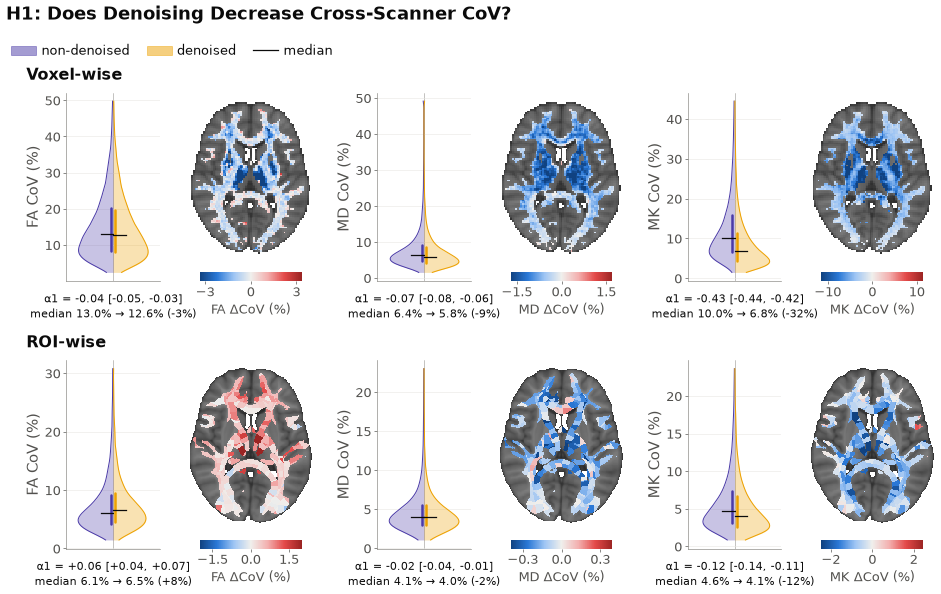

In [3]:
fig = figs.fig_h1(DERIV, METRICS, z=8, fs=16)
figs.save(fig, FIGS, "Fig2_H1")
plt.show()

## Exploratory results

In [4]:
import build_inputs as B  # noqa: E402
import inputs as I  # noqa: E402

ARMS = B.ARMS
EXAMPLE = "sub-16975"


def split(x):
    """x: (T scanners, R units) -> total, systematic, unit-specific (%^2), offset and RMS scatter per scanner (%)."""
    d = 100 * (x - x.mean(0)) / x.mean(0)
    d = d[:, np.isfinite(d).all(0) & (x.mean(0) > 0)]
    T = d.shape[0]
    off = d.mean(1)
    total = (d ** 2).sum(0).mean() / (T - 1)
    syst = (off ** 2).sum() / (T - 1)
    return total, syst, total - syst, off, np.sqrt(((d - off[:, None]) ** 2).mean(1))


def cov_pct(x):
    return I.cov(x) * 100


D = B.Data(DERIV, MANIFEST)
dec, offs, by_subject, shift, example = [], [], [], [], {}
for sub in sorted(D.sessions):
    sess = D.sessions[sub]
    scanners = [sc for _, sc in sess]
    rids = B.roi_ids(D.template(sub, "all") / "T_xtract_rois_counts.csv")
    for m in METRICS:
        u = B.subject_units(D, sub, "all", sess, m, {}, "explore")
        sel = u["lat"] & u["keep"]
        per = {}
        for arm in ARMS:
            v = u["vals"][arm]
            roi, nk, _ = I.roi_means(v, u["lab"], u["keep"], rids)
            for lvl, x in (("voxel", v[:, sel]), ("ROI", roi)):
                per[lvl, arm], labs = I.average_by_group(x, scanners)
                tot, syst, res, off, jit = split(per[lvl, arm])
                dec.append(dict(subject=sub, metric=m, level=lvl, arm=arm, total=tot, systematic=syst,
                                unit_specific=res))
                offs += [dict(subject=sub, metric=m, level=lvl, arm=arm, scanner=sc, offset_pct=o, jitter_pct=j)
                         for sc, o, j in zip(labs, off, jit)]
                if sub == EXAMPLE:
                    dd = 100 * (per[lvl, arm] - per[lvl, arm].mean(0)) / per[lvl, arm].mean(0)
                    example[f"{m}_{lvl}_{arm}"] = dd[:, np.isfinite(dd).all(0) & (per[lvl, arm].mean(0) > 0)].astype(np.float32)
                    example["scanners"] = np.array(labs)
        # ROI-wise and voxel-wise Delta CoV per subject; ROIs with no voxels are dropped
        ok = nk > 0
        S = {arm: per["ROI", arm][:, ok] for arm in ARMS}
        c0, c1 = I.missing_in_either_arm(cov_pct(S[ARMS[0]]), cov_pct(S[ARMS[1]]))
        v0, v1 = I.missing_in_either_arm(cov_pct(per["voxel", ARMS[0]]), cov_pct(per["voxel", ARMS[1]]))
        dr, dv = c1 - c0, v1 - v0
        by_subject.append(dict(subject=sub, metric=m, n_roi=int(np.isfinite(dr).sum()),
                               roi_dcov_median_pp=float(np.nanmedian(dr)), roi_pct_increased=100 * float(np.nanmean(dr > 0)),
                               vox_dcov_median_pp=float(np.nanmedian(dv)), vox_pct_increased=100 * float(np.nanmean(dv > 0))))
        V = {arm: per["voxel", arm] for arm in ARMS}
        for k, sc in enumerate(labs):
            shift.append(dict(subject=sub, scanner=sc, metric=m,
                              roi_shift_pct_median=100 * float(np.nanmedian((S[ARMS[1]][k] - S[ARMS[0]][k]) / S[ARMS[0]][k])),
                              vox_shift_pct_median=100 * float(np.nanmedian((V[ARMS[1]][k] - V[ARMS[0]][k]) / V[ARMS[0]][k]))))

dec, offs, by_subject, shift = map(pd.DataFrame, (dec, offs, by_subject, shift))
for folder, files in (("H1_spread", {"decomposition": dec, "offsets": offs}),
                      ("H1_roi_diag", {"A_by_subject": by_subject, "C_scanner_shift": shift})):
    (EXPL / folder).mkdir(parents=True, exist_ok=True)
    for name, t in files.items():
        t.to_csv(EXPL / folder / f"{name}.csv", index=False)
np.savez_compressed(EXPL / "H1_spread" / f"example_{EXAMPLE}.npz", **example)

In [5]:
t = dec.groupby(["metric", "level", "arm"])[["total", "systematic", "unit_specific"]].mean().unstack("arm")
t.reindex(["voxel", "ROI"], level="level").round(1)

total             systematic             unit_specific            
arm          denoised nondenoised   denoised nondenoised      denoised nondenoised
metric level                                                                      
FA     voxel    340.9       348.1       14.9        10.8         326.0       337.3
       ROI       95.5        91.1       14.2        10.9          81.4        80.2
MD     voxel    110.0       117.9        4.2         4.3         105.8       113.6
       ROI       41.4        42.3        3.4         3.5          38.0        38.7
MK     voxel    141.8       250.8        3.0         2.7         138.8       248.1
       ROI       49.4        58.5        2.2         1.9          47.1        56.6

In [6]:
dec[(dec.subject == EXAMPLE) & (dec.metric == "FA") & (dec.level == "ROI")].round(1)

,subject,metric,level,arm,total,systematic,unit_specific
97,sub-16975,FA,ROI,nondenoised,87.1,10.6,76.5
99,sub-16975,FA,ROI,denoised,93.7,16.1,77.6


In [7]:
a = by_subject[by_subject.metric == "FA"]
print(f"ROI-wise FA median ΔCoV per subject: {a.roi_dcov_median_pp.min():+.2f} to {a.roi_dcov_median_pp.max():+.2f} pp; "
      f"ROIs increased {a.roi_pct_increased.min():.0f}-{a.roi_pct_increased.max():.0f}%; "
      f"increase in {(a.roi_dcov_median_pp > 0).sum()}/{len(a)} subjects")

ROI-wise FA median ΔCoV per subject: +0.16 to +0.45 pp; ROIs increased 61-72%; increase in 10/10 subjects


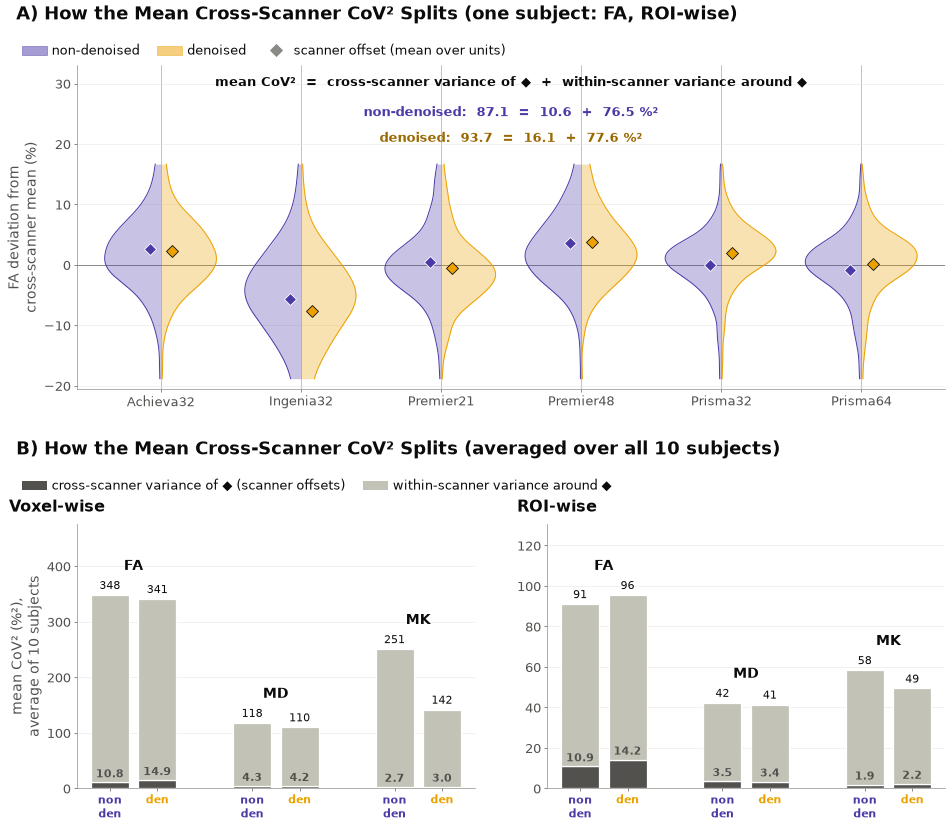

In [8]:
fig = figs.figx_h1(DERIV, METRICS, fs=16)
figs.save(fig, FIGS, "Fig6_H1_exploratory")
plt.show()